# GARCH validation

**Question.** The var1 validation (`var1/03_validation.ipynb`) found bands that are too wide in calm years and too narrow in 2021-22. Does replacing the constant residual volatility with a daily conditional volatility fix that?

**Answer in brief.** GARCH removes the volatility clustering in the daily residuals and modestly improves daily-std calibration, but it does not improve 250-day coverage. The horizon gap comes from short-end trending and regime changes, not from the daily variance (see the variance-ratio section and the findings at the end).

## Method

Both models are fitted on the same data and scored on the same windows (the var1 model is re-run for the side-by-side comparison). The shared workflow for all models is in `model_comparison.ipynb`.

1. Variance ratio of the 250-day change, simulated against realised.
2. Design A: single cut (end-2018).
3. Design B: expanding window, origins at every year-end 2012-2022.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from scenario_lab.data import load_curve
from scenario_lab.models import var1 as m, var1_garch as gm
from scenario_lab.models.sigma_garch import Garch11
from scenario_lab import validation as v
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"

levels = load_curve("AAA")
changes = levels.diff().dropna()
realised = v.realised_changes(levels)
FIT_END = v.FIT_END
mats = list(levels.columns)
print("fit end:", FIT_END, "| daily changes:", changes.shape)

fit end: 2018-12-31 | daily changes: (5677, 6)


In [2]:
pg = gm.fit(changes)                                  # GARCH layer, full sample
pb = m.fit(changes)                                   # constant-volatility baseline
y0 = levels.iloc[-1].values
cg = gm.simulate(pg, y0, seed=0)
cb = m.simulate(pb, y0, seed=0)

### Variance ratio of the 250-day change

`VR = var(250-day change) / (250 * var(daily change))`. VR = 1 when daily changes are uncorrelated, above 1 when the spread accumulates faster (trending). Realised values use all overlapping 250-day windows; simulated values use the paths above. A gap between realised and simulated VR cannot be closed by a better daily volatility.

In [3]:
vr_real = realised.var() / (250 * changes.var())
vr_m2 = pd.Series((cb[:, -1] - y0).var(0) / (250 * np.diff(cb, axis=1).reshape(-1, 6).var(0)), index=mats)
vr_g = pd.Series((cg[:, -1] - y0).var(0) / (250 * np.diff(cg, axis=1).reshape(-1, 6).var(0)), index=mats)
print(pd.DataFrame({"realised": vr_real, "var1": vr_m2, "GARCH": vr_g}).round(2))

     realised  var1  GARCH
1Y       5.68  1.14   1.18
2Y       2.45  1.11   1.14
5Y       1.39  1.04   1.06
10Y      1.20  1.04   1.06
20Y      1.07  1.09   1.12
30Y      0.88  1.10   1.13


## Design A: single cut (end-2018)

Fit on data up to the cut, simulate from that curve, compare with the realised 250-day changes starting at or after the cut (as in `var1/03_validation.ipynb`). var1 is re-run so both models are scored on the same windows. Coverage is the fraction of realised changes inside the simulated band (nominal 0.90 for 5-95%, 0.50 for 25-75%).

In [4]:
y0_a = levels.loc[:FIT_END].iloc[-1].values
pa_g = gm.fit(changes.loc[:FIT_END]); pa_b = m.fit(changes.loc[:FIT_END])
cg_a = gm.simulate(pa_g, y0_a, seed=0); cb_a = m.simulate(pa_b, y0_a, seed=0)
sim_g = cg_a[:, -1] - cg_a[:, 0]; sim_b = cb_a[:, -1] - cb_a[:, 0]

test = realised.loc[FIT_END:]
train = realised.loc[:FIT_END].iloc[:-250]
print("test windows:", len(test), "(about", round(len(test) / 250, 1), "independent years)")
for band, (lo, hi), nom in [("5-95%", (0.05, 0.95), 0.9), ("25-75%", (0.25, 0.75), 0.5)]:
    print(f"\ncoverage {band} (nominal {nom:.0%})")
    print(pd.DataFrame({"var1 test": v.coverage(sim_b, test, lo, hi), "GARCH test": v.coverage(sim_g, test, lo, hi),
                        "var1 train": v.coverage(sim_b, train, lo, hi), "GARCH train": v.coverage(sim_g, train, lo, hi)}).round(3))

test windows: 1764 (about 7.1 independent years)

coverage 5-95% (nominal 90%)
     var1 test  GARCH test  var1 train  GARCH train
1Y       0.563       0.520       0.734        0.711
2Y       0.708       0.632       0.809        0.756
5Y       0.789       0.756       0.873        0.798
10Y      0.811       0.794       0.912        0.829
20Y      0.840       0.823       0.942        0.878
30Y      0.885       0.852       0.967        0.938

coverage 25-75% (nominal 50%)
     var1 test  GARCH test  var1 train  GARCH train
1Y       0.397       0.372       0.489        0.412
2Y       0.494       0.471       0.546        0.452
5Y       0.573       0.518       0.483        0.413
10Y      0.544       0.458       0.538        0.467
20Y      0.536       0.455       0.598        0.517
30Y      0.580       0.491       0.644        0.536


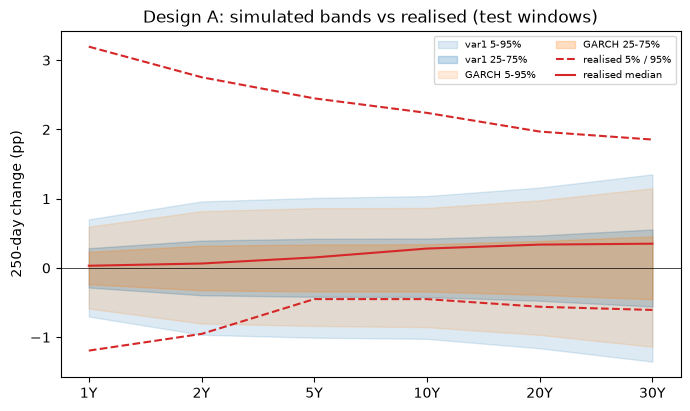

In [5]:
qb, qg = v.horizon_quantiles(cb_a), v.horizon_quantiles(cg_a)
rq = test.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
x = np.arange(len(mats))
fig, ax = plt.subplots(figsize=(8, 4.5))
for q, c, name in [(qb, "C0", "var1"), (qg, "C1", "GARCH")]:
    ax.fill_between(x, q.loc[0.05], q.loc[0.95], alpha=0.15, color=c, label=f"{name} 5-95%")
    ax.fill_between(x, q.loc[0.25], q.loc[0.75], alpha=0.25, color=c, label=f"{name} 25-75%")
ax.plot(x, rq.loc[0.05], "C3--", label="realised 5% / 95%"); ax.plot(x, rq.loc[0.95], "C3--")
ax.plot(x, rq.loc[0.5], "C3-", label="realised median")
ax.axhline(0, color="k", lw=0.5); ax.set_xticks(x); ax.set_xticklabels(mats)
ax.set_ylabel("250-day change (pp)"); ax.set_title("Design A: simulated bands vs realised (test windows)")
ax.legend(fontsize=7, ncol=2); plt.show()

## Design B: expanding window (origins at every year-end 2012-2022)

At each origin both models are fitted on data up to the origin, simulated for 250 days, and scored on the 250 windows starting in the following year. Outputs: pooled and per-origin coverage, and the ratio of simulated to actual daily std in the test year.

In [6]:
origins = [f"{y}-12-31" for y in range(2012, 2023)]
res = {k: {"c90": {}, "c50": {}, "sim_std": {}} for k in ["var1", "GARCH"]}
act_std = {}
for o in origins:
    ch_o, y0_o = changes.loc[:o], levels.loc[:o].iloc[-1].values
    test_o = realised[realised.index > o].iloc[:250]
    act_std[o] = changes[changes.index > o].iloc[:250].std().values
    for name, curves_o in [("var1", m.simulate(m.fit(ch_o), y0_o)), ("GARCH", gm.simulate(gm.fit(ch_o), y0_o))]:
        sim_o = curves_o[:, -1] - curves_o[:, 0]
        res[name]["c90"][o] = v.coverage(sim_o, test_o, 0.05, 0.95)
        res[name]["c50"][o] = v.coverage(sim_o, test_o, 0.25, 0.75)
        res[name]["sim_std"][o] = np.diff(curves_o, axis=1).reshape(-1, 6).std(axis=0)
t90 = {k: pd.DataFrame(v["c90"]).T for k, v in res.items()}
t50 = {k: pd.DataFrame(v["c50"]).T for k, v in res.items()}
print("pooled 5-95% coverage by maturity (nominal 0.90)")
print(pd.DataFrame({k: t.mean() for k, t in t90.items()}).T.round(3))
print("\nmean |coverage - nominal|, all origins and maturities")
print(pd.DataFrame({"5-95%": {k: (t90[k] - 0.9).abs().values.mean() for k in t90},
                    "25-75%": {k: (t50[k] - 0.5).abs().values.mean() for k in t50}}).round(3))

pooled 5-95% coverage by maturity (nominal 0.90)
          1Y     2Y     5Y    10Y    20Y    30Y
var1   0.831  0.853  0.870  0.822  0.842  0.896
GARCH  0.842  0.852  0.865  0.785  0.805  0.869

mean |coverage - nominal|, all origins and maturities
       5-95%  25-75%
var1   0.185   0.321
GARCH  0.193   0.316


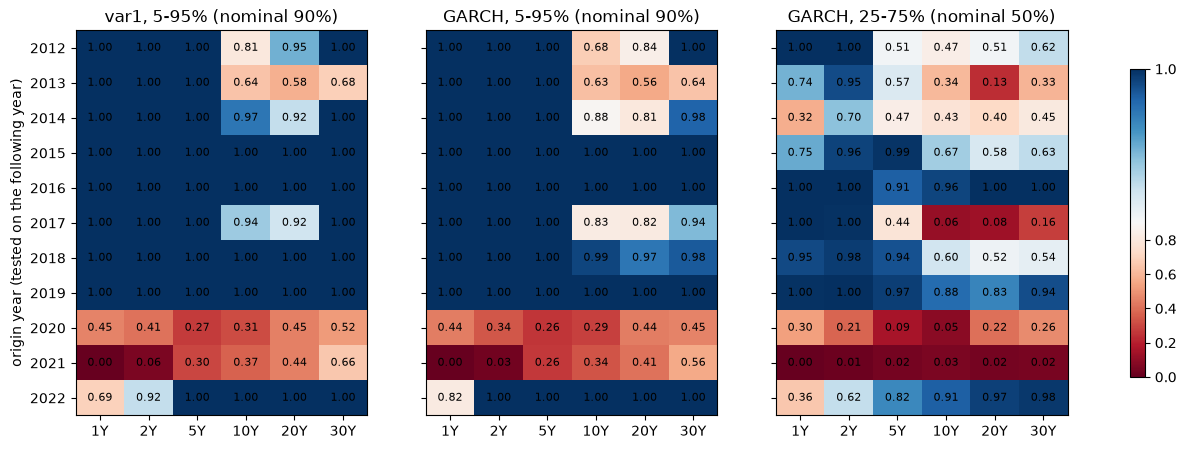

In [7]:
def heat(ax, tab, nominal, title):
    im = ax.imshow(tab.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=nominal, vmin=0, vmax=1), aspect="auto")
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels([o[:4] for o in tab.index])
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title); return im

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
heat(axes[0], t90["var1"], 0.9, "var1, 5-95% (nominal 90%)")
im = heat(axes[1], t90["GARCH"], 0.9, "GARCH, 5-95% (nominal 90%)")
heat(axes[2], t50["GARCH"], 0.5, "GARCH, 25-75% (nominal 50%)")
axes[0].set_ylabel("origin year (tested on the following year)")
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

GARCH simulated / actual daily std
              1Y    2Y    5Y   10Y   20Y   30Y
2012-12-31  2.03  1.59  1.01  0.89  1.05  1.26
2013-12-31  2.65  2.66  1.64  1.25  1.23  1.57
2014-12-31  1.81  2.25  1.25  0.71  0.59  0.69
2015-12-31  2.38  2.75  1.66  1.16  0.95  1.01
2016-12-31  1.69  2.10  1.55  1.27  1.23  1.39
2017-12-31  2.11  2.19  1.46  1.33  1.46  1.67
2018-12-31  1.77  2.06  1.43  1.08  0.96  1.04
2019-12-31  1.27  1.34  1.05  0.91  0.90  0.97
2020-12-31  2.00  2.07  1.37  1.19  1.22  1.39
2021-12-31  0.44  0.40  0.42  0.47  0.53  0.63
2022-12-31  0.62  0.67  0.77  0.79  0.84  0.98

M2 simulated / actual daily std
              1Y    2Y    5Y   10Y   20Y   30Y
2012-12-31  2.25  1.76  1.13  1.01  1.17  1.40
2013-12-31  2.94  2.97  1.82  1.36  1.37  1.75
2014-12-31  1.99  2.49  1.40  0.80  0.66  0.76
2015-12-31  2.38  2.75  1.65  1.16  0.95  1.01
2016-12-31  1.62  2.04  1.56  1.31  1.26  1.40
2017-12-31  2.36  2.44  1.62  1.48  1.62  1.86
2018-12-31  2.00  2.35  1.66  1.26  1.1

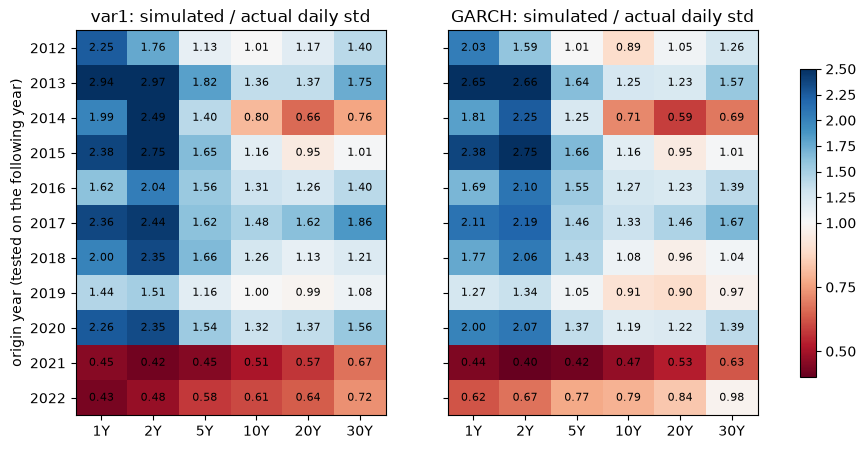

mean |log ratio|  (0 = calibrated): {'var1': 0.482, 'GARCH': 0.409}


In [8]:
ratio = {k: pd.DataFrame(v["sim_std"], index=mats).T / pd.DataFrame(act_std, index=mats).T for k, v in res.items()}
print("GARCH simulated / actual daily std")
print(ratio["GARCH"].round(2))
print("\nM2 simulated / actual daily std")
print(ratio["var1"].round(2))
print("\nGARCH 5-95% coverage by origin")
print(t90["GARCH"].round(2))
print("\nM2 5-95% coverage by origin")
print(t90["var1"].round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, k in zip(axes, ["var1", "GARCH"]):
    r = ratio[k]
    im = ax.imshow(r.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=1, vmin=0.4, vmax=2.5), aspect="auto")
    ax.set_xticks(range(6)); ax.set_xticklabels(mats)
    ax.set_yticks(range(len(r))); ax.set_yticklabels([o[:4] for o in r.index])
    for a in range(r.shape[0]):
        for b in range(r.shape[1]):
            ax.text(b, a, f"{r.values[a, b]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{k}: simulated / actual daily std")
axes[0].set_ylabel("origin year (tested on the following year)")
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()
print("mean |log ratio|  (0 = calibrated):", {k: round(float(np.abs(np.log(r.values)).mean()), 3) for k, r in ratio.items()})

## Findings

### Estimation
- **Volatility clustering is mostly removed.** Ljung-Box p on squared residuals goes from about 0 (raw) to 0.30 (PC1) and 0.35 (PC3) after standardising; PC2 keeps some (p = 0.007).
- **Persistence is near 1:** alpha + beta = 0.993-0.996, nu = 4.4-9.1. A volatility shock decays over roughly 100-200 days, so a 250-day simulation largely retains the starting state.
- **Today's state is calm:** current sigma is 0.07 / 0.04 / 0.01 against long-run 0.09 / 0.05 / 0.02, so GARCH bands are slightly narrower than var1's (250-day std 0.47-0.75 against 0.46-0.78).

### Design A (cut at end-2018)
- GARCH coverage on the test windows is **lower than var1 at every maturity** (5-95%: 1Y 0.52 against 0.56, 10Y 0.79 against 0.81, 30Y 0.85 against 0.89). End-2018 was a calm state, so GARCH starts narrower, and the 2022 hikes fall outside the bands.

### Design B (expanding window)
- **Daily-std calibration improves modestly:** mean |log ratio| 0.48 (var1) to 0.41 (GARCH). The gain appears once turbulence has started: at origin 2022 the ratio goes from 0.43-0.72 to 0.62-0.98 and 1Y coverage from 0.69 to 0.82.
- **The two var1 failures remain.** Calm years at 1Y-2Y are still 1.3-2.8 times too volatile (var1: 1.4-3.0), and the 2020-21 origins stay too narrow (origin 2021, 1Y coverage 0.00 for both models).
- **Horizon coverage does not improve:** mean |coverage - nominal| is 0.193 (GARCH) against 0.185 (var1) for the 5-95% band, 0.316 against 0.321 for 25-75%. Pooled 5-95% coverage at 10Y-30Y is lower (0.79-0.87 against 0.82-0.90).

### Why the horizon gap remains
- **The spread accumulates faster than the daily volatility implies.** The realised variance ratio is 5.7 (1Y), 2.5 (2Y), 1.4 (5Y), 1.2 (10Y), 1.1 (20Y), 0.9 (30Y); both simulations give 1.0-1.2. Short-end rates trend over months, which neither var1 nor GARCH reproduces, so a better daily sigma cannot close the 1Y-2Y gap. This is why GARCH's daily improvement does not carry over to 250-day coverage.
- **GARCH reacts but does not anticipate.** At the end of 2021 volatility was still low, so any model driven by past shocks starts narrow; the 2022 hikes were a regime change.
- **Calm-year overwidth at the short end** (2012-2019) is not explained by clustering: GARCH barely changes it. Candidate causes, not tested here, are the fixed PCA loadings and the floor effect on short rates.

### Limitations
- About 7 to 11 independent years: differences of a few hundredths in coverage are not meaningful, and each Design B row is essentially one yes/no outcome per year.

### Conclusion
GARCH fixes the daily volatility clustering but not the 250-day miscalibration. It is kept as the GARCH baseline. The remaining gaps (short-end trending, regime changes) are not variance-model problems; the mean-dynamics variants in `scratch/a_var_lags` and `scratch/b_arma_drift` test one candidate fix.